# ARTI 403 Image Processing
## Lab 9: Morphological Operations

Name: Mohammed Saeed Alamodi
ID: 2240009007

I used the Balls image. The balls are black on a white background, so I inverted the threshold to make the balls white (the foreground). I also shrank the image to a third of its size so the small kernels have a visible effect.

## Task 1: Morphological Operations on a New Image

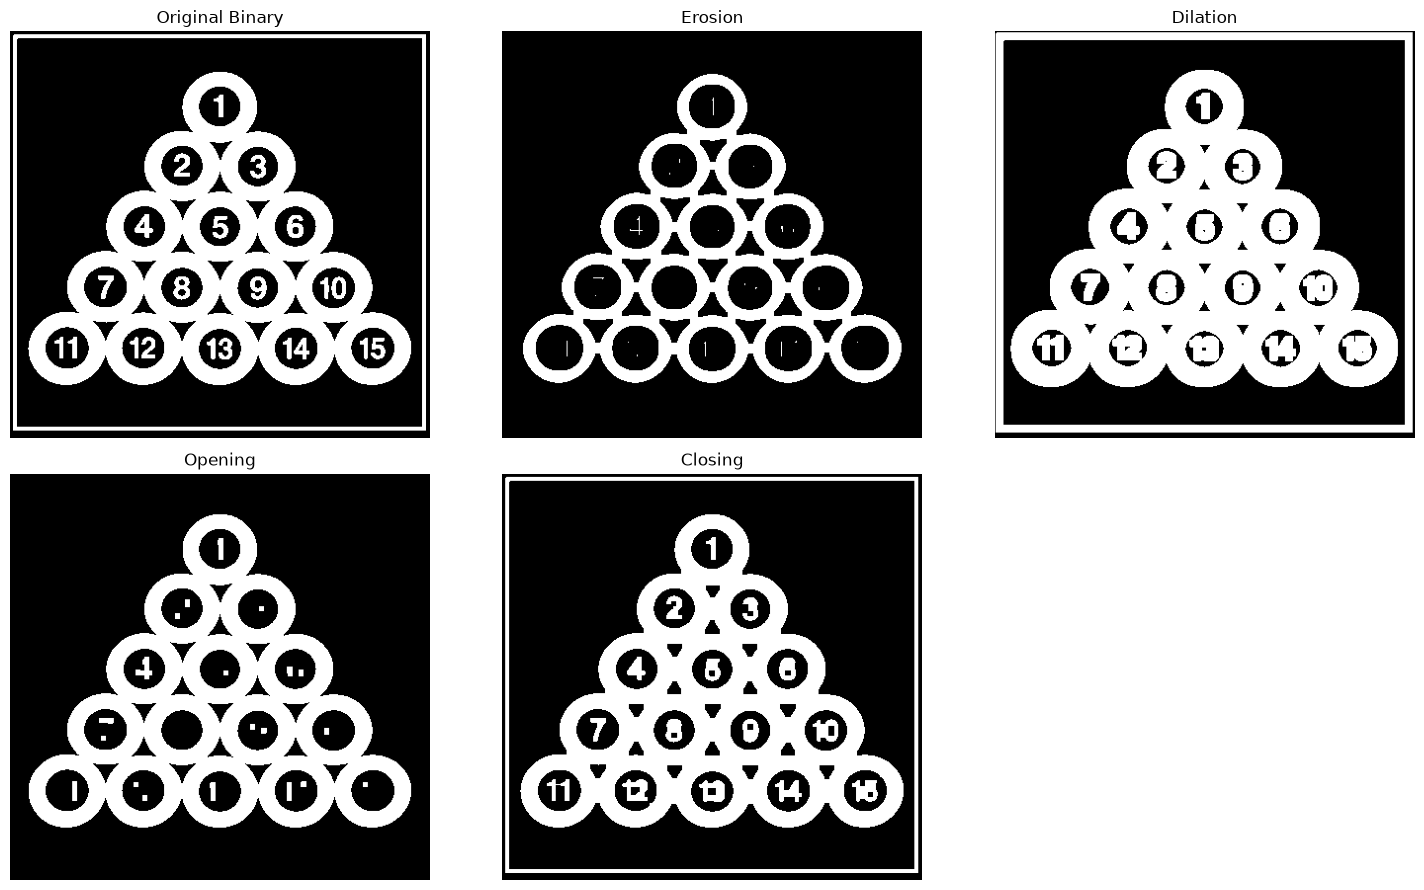

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('Balls.png', 0)
img = cv2.resize(img, None, fx=1/3, fy=1/3, interpolation=cv2.INTER_AREA)

# Otsu threshold, inverted so the balls are white
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(binary, kernel)
dilation = cv2.dilate(binary, kernel)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

titles = ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [binary, erosion, dilation, opening, closing]

plt.figure(figsize=(15, 9))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Erosion makes the white balls thinner and wipes out the thin white numbers inside them. Dilation does the opposite: the balls get thicker, the numbers fill in and the border frame grows. Opening (erosion then dilation) removes the thin numbers but keeps the balls at about their original size. Closing (dilation then erosion) keeps the balls the same size, but the numbers get blobby and the little gaps between the balls close up.

## Task 2: Structuring Elements

Erosion  Square   3x3: 44377 white pixels
Erosion  Square   5x5: 33409 white pixels
Erosion  Square   7x7: 26804 white pixels
Erosion  Cross    3x3: 46639 white pixels
Erosion  Cross    5x5: 37803 white pixels
Erosion  Cross    7x7: 33002 white pixels
Erosion  Ellipse  3x3: 46639 white pixels
Erosion  Ellipse  5x5: 35980 white pixels
Erosion  Ellipse  7x7: 31107 white pixels


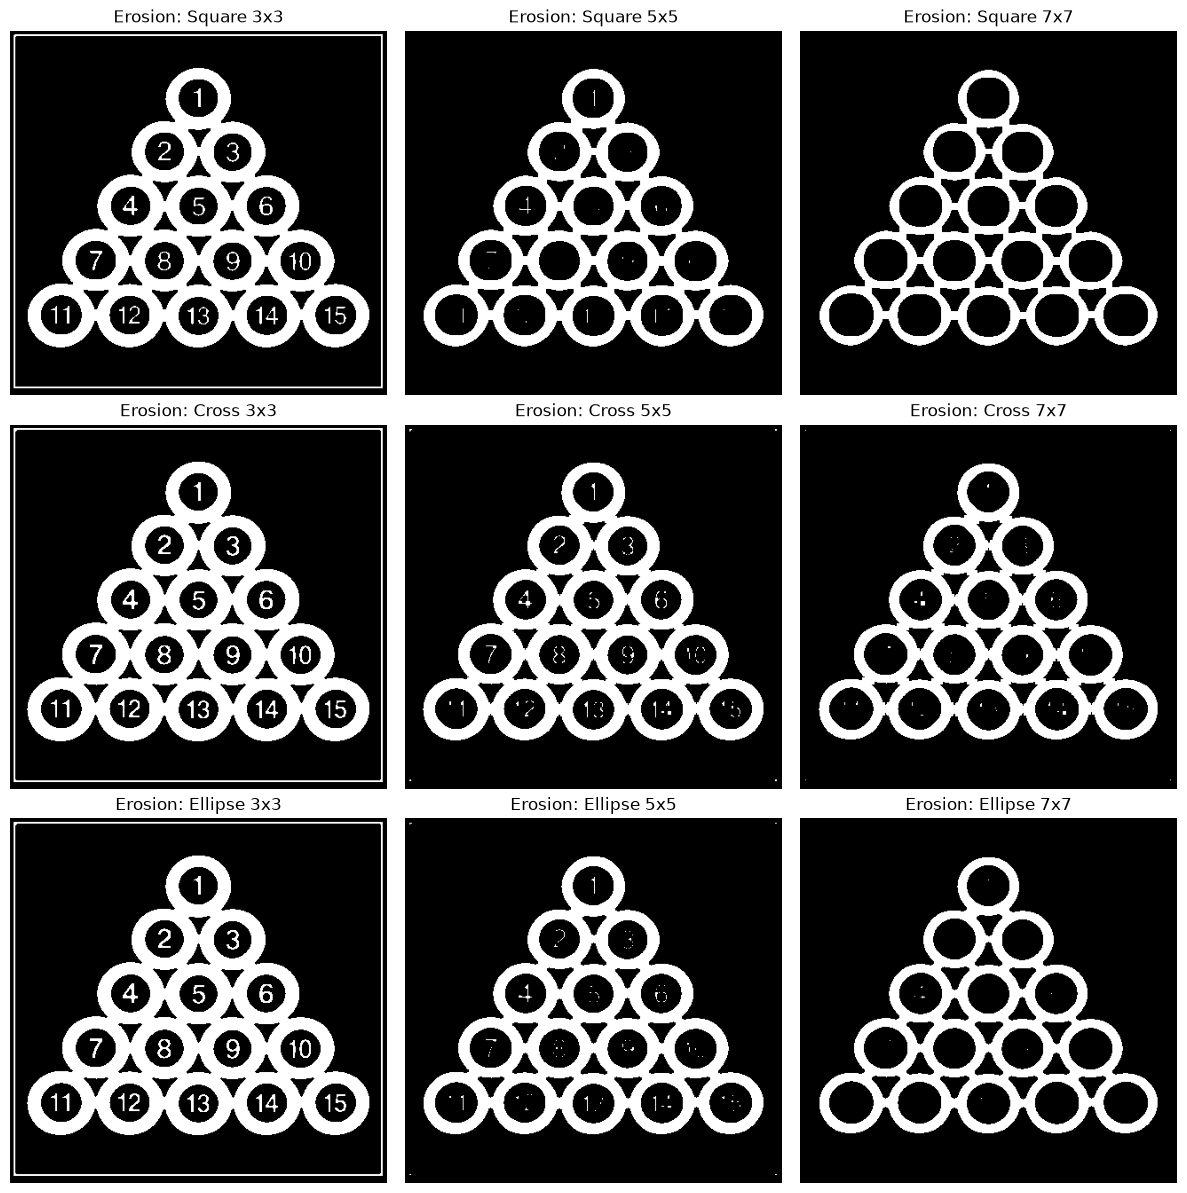

Dilation Square   3x3: 66617 white pixels
Dilation Square   5x5: 76870 white pixels
Dilation Square   7x7: 86153 white pixels
Dilation Cross    3x3: 64533 white pixels
Dilation Cross    5x5: 72983 white pixels
Dilation Cross    7x7: 80895 white pixels
Dilation Ellipse  3x3: 64533 white pixels
Dilation Ellipse  5x5: 74498 white pixels
Dilation Ellipse  7x7: 82509 white pixels


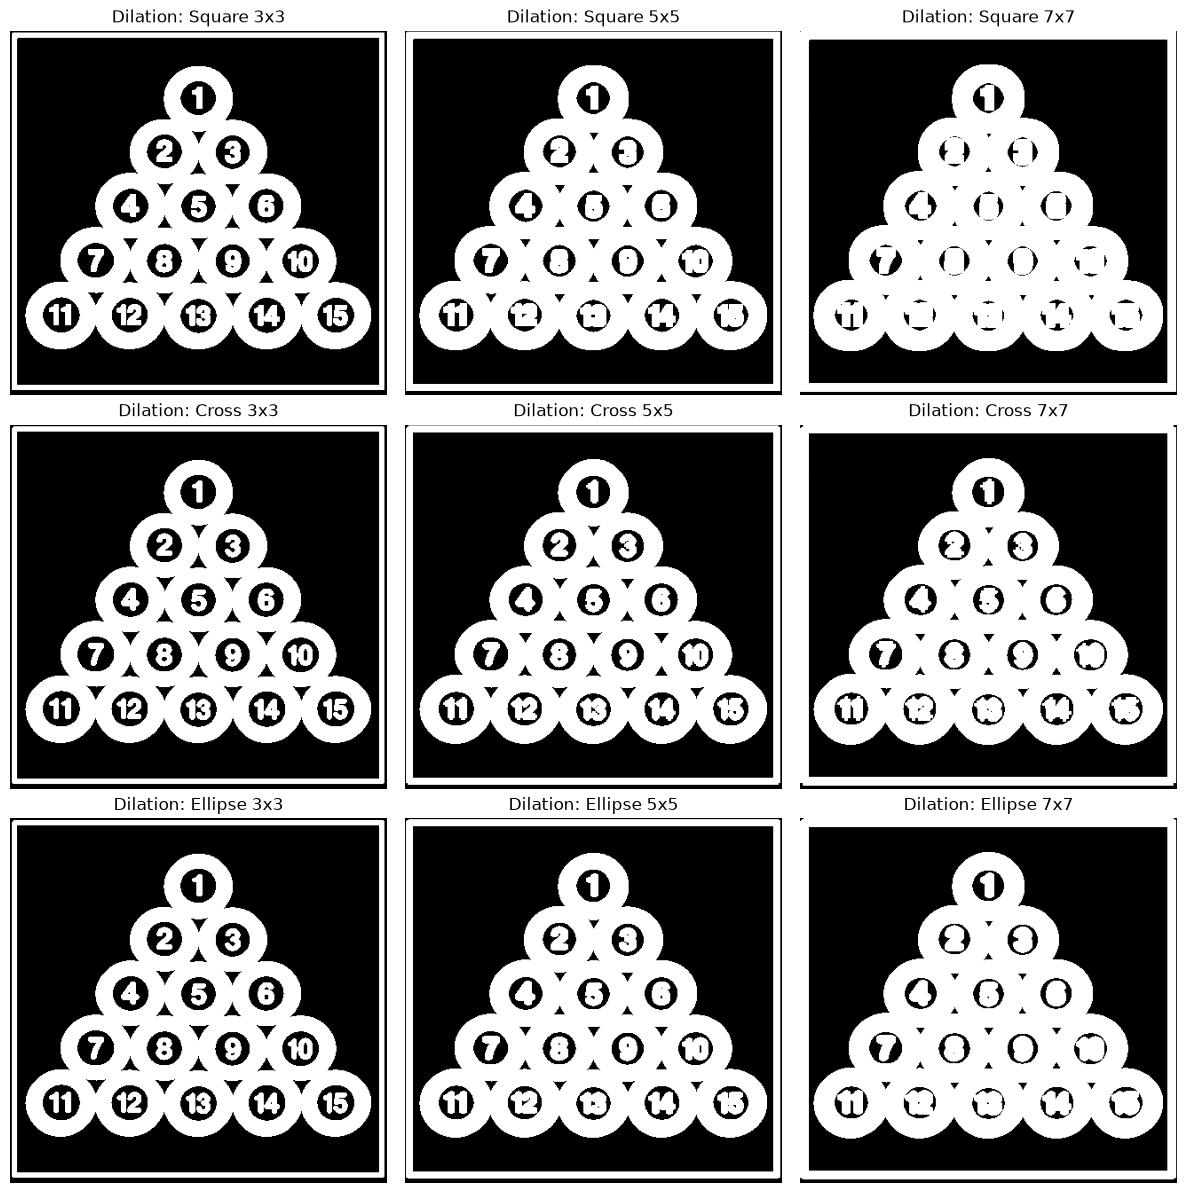

Original: 55630 white pixels


In [2]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

for name, op in [('Erosion', cv2.erode), ('Dilation', cv2.dilate)]:
    fig, ax = plt.subplots(3, 3, figsize=(12, 12))
    for r, (shape, flag) in enumerate(shapes.items()):
        for col, s in enumerate(sizes):
            k = cv2.getStructuringElement(flag, (s, s))
            out = op(binary, k)
            ax[r, col].imshow(out, 'gray')
            ax[r, col].set_title(f'{name}: {shape} {s}x{s}')
            ax[r, col].axis('off')
            print(f'{name:8s} {shape:8s} {s}x{s}: {np.count_nonzero(out)} white pixels')
    plt.tight_layout()
    plt.show()

print('Original:', np.count_nonzero(binary), 'white pixels')

A bigger kernel always changes the image more. Erosion drops from 55,630 white pixels in the original to 44,377 (3x3), 33,409 (5x5) and 26,804 (7x7) with the square. Dilation goes up the same way, to 86,153 at 7x7. The square kernel is the strongest, the ellipse is in the middle and the cross is the weakest (for example 33,002 for the cross against 26,804 for the square after a 7x7 erosion). With the square at 7x7 all the numbers are gone and only the rings are left, while the cross still keeps small bits of them. At 3x3 the cross and the ellipse give exactly the same result because they are the same 3x3 shape.